# Customer Retention Intelligence — Model Comparison

## Objective
Compare five **untuned baseline** models for `churn_next_30_days` --
Logistic Regression and Random Forest (Phase 5) plus XGBoost, LightGBM, and
CatBoost (new this phase) -- using exactly the same chronological split,
feature set, target definition, preprocessing rules, and evaluation
methodology as Phase 5. No hyperparameter tuning, threshold optimization,
SHAP, or MLflow here -- this notebook only compares baselines to decide
which model is worth tuning in Phase 7.

**Primary metric: PR-AUC (average precision).** With a ~1-2% positive
class, PR-AUC reflects how well a model ranks the rare churn class far
better than ROC-AUC does, and is what the Phase 7 recommendation is based
on. This notebook does not declare any model "production-ready" -- that
requires tuning, threshold selection, and further validation beyond this
phase's scope.


In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

from src.models import baseline as bl
from src.models import model_comparison as mc

PROJECT_ROOT


PosixPath('/Users/dhananjaymandal/customer-retention-intelligence')

## 2. Load Feature Data

The same Phase 4 feature dataset used in Phase 5:
`data/processed/customer_features.parquet`.


In [2]:
features = bl.load_feature_dataset()
print("shape:", features.shape)
features.head()


shape: (136701, 134)


,customer_id,snapshot_date,age,country,plan,contract_type,acquisition_channel,tenure_days,tenure_months,txn_count_30d,txn_amount_sum_30d,txn_amount_mean_30d,txn_amount_max_30d,txn_success_count_30d,txn_failed_count_30d,...,high_critical_ticket_count_180d,avg_satisfaction_180d,min_satisfaction_180d,avg_resolution_hours_180d,max_resolution_hours_180d,category_account_count_180d,category_billing_count_180d,category_feature_request_count_180d,category_login_count_180d,category_other_count_180d,category_performance_count_180d,category_technical_count_180d,days_since_last_ticket,has_any_support_history,churn_next_30_days
0,C000001,2025-05-31,69,United States,Basic,Monthly,Referral,21,0.69,1.0,35.71,35.710,35.71,1.0,0.0,...,0.0,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,False,0
1,C000001,2025-06-30,69,United States,Basic,Monthly,Referral,51,1.68,1.0,28.20,28.200,28.20,1.0,0.0,...,0.0,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,False,0
2,C000001,2025-07-31,69,United States,Basic,Monthly,Referral,82,2.69,0.0,0.00,NaN,NaN,0.0,0.0,...,0.0,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,False,0
3,C000001,2025-08-31,69,United States,Basic,Monthly,Referral,113,3.71,1.0,37.69,37.690,37.69,1.0,0.0,...,0.0,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,False,0
4,C000001,2025-09-30,69,United States,Basic,Monthly,Referral,143,4.70,2.0,73.71,36.855,37.49,2.0,0.0,...,0.0,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,False,0


## 3. Reproduce Chronological Split

The identical train/validation/test split from Phase 5
(`src/models/baseline.split_by_snapshot_date`) -- never a random split.

| Split | Snapshot dates |
|---|---|
| Train | 2025-01-31 -> 2025-11-30 |
| Validation | 2025-12-31 -> 2026-02-28 |
| Test | 2026-03-31 -> 2026-05-31 |


In [3]:
splits = bl.split_by_snapshot_date(features)

assert sum(len(df) for df in splits.values()) == len(features)
assert splits["train"]["snapshot_date"].max() < splits["validation"]["snapshot_date"].min()
assert splits["validation"]["snapshot_date"].max() < splits["test"]["snapshot_date"].min()

split_summary = pd.DataFrame([bl.summarize_split(name, df) for name, df in splits.items()])
split_summary


,split,rows,unique_customers,positive_count,negative_count,positive_pct,min_snapshot_date,max_snapshot_date
0,train,85419,9454,820,84599,0.960,2025-01-31,2025-11-30
1,validation,26337,8917,448,25889,1.701,2025-12-31,2026-02-28
2,test,24945,8478,402,24543,1.612,2026-03-31,2026-05-31


In [4]:
numeric_columns, categorical_columns = bl.get_feature_columns(features)
feature_columns = numeric_columns + categorical_columns

X_train = splits["train"][feature_columns]
y_train = splits["train"][bl.TARGET_COLUMN]
X_validation = splits["validation"][feature_columns]
y_validation = splits["validation"][bl.TARGET_COLUMN]
X_test = splits["test"][feature_columns]
y_test = splits["test"][bl.TARGET_COLUMN]

print(f"Feature columns: {len(feature_columns)} ({len(numeric_columns)} numeric, {len(categorical_columns)} categorical)")
print(X_train.shape, X_validation.shape, X_test.shape)


Feature columns: 131 (127 numeric, 4 categorical)
(85419, 131) (26337, 131) (24945, 131)


## 4. Load / Train Models

All five pipelines share the identical preprocessing recipe from
`src/models/baseline.build_preprocessor` (median-impute + scale numeric,
most-frequent-impute + one-hot-encode categorical), each fit **only on
`X_train`** -- validation and test are only ever transformed.

**Imbalance strategy per model** (~1-2% positive rate; no hyperparameter
tuning applied to any of them):

| Model | Imbalance handling |
|---|---|
| Logistic Regression | `class_weight="balanced"` |
| Random Forest | `class_weight="balanced"` |
| XGBoost | `scale_pos_weight` = negative/positive ratio computed from the training split |
| LightGBM | `class_weight="balanced"` |
| CatBoost | `auto_class_weights="Balanced"` |

Each is that library's own native, documented mechanism for the same
underlying idea: inversely weight the loss by class frequency.


In [5]:
experiment = mc.run_comparison_experiment(features)
pipelines = experiment["pipelines"]
print("Trained models:", list(pipelines.keys()))


Trained models: ['logistic_regression', 'random_forest', 'xgboost', 'lightgbm', 'catboost']


## 5. Validation Results

All metrics use the fixed threshold of 0.5 -- threshold optimization is
explicitly out of scope for this phase.


In [6]:
results = experiment["results"]
validation_results = results[results["split"] == "validation"].set_index("model")
validation_results[["pr_auc", "roc_auc", "precision", "recall", "f1"]].sort_values("pr_auc", ascending=False)


,pr_auc,roc_auc,precision,recall,f1
model,,,,,
logistic_regression,0.028075,0.619702,0.020848,0.741071,0.040555
random_forest,0.023185,0.558722,0.026368,0.238839,0.047492
lightgbm,0.022886,0.534180,0.023799,0.238839,0.043285
catboost,0.021320,0.551053,0.020492,0.345982,0.038692
xgboost,0.020236,0.520614,0.020842,0.223214,0.038124


## 6. Test Results

The test split (2026-03-31 -> 2026-05-31) was not used to fit, select, or
adjust any model up to this point.


In [7]:
test_results = results[results["split"] == "test"].set_index("model")
test_results[["pr_auc", "roc_auc", "precision", "recall", "f1"]].sort_values("pr_auc", ascending=False)


,pr_auc,roc_auc,precision,recall,f1
model,,,,,
logistic_regression,0.037655,0.668745,0.020101,0.830846,0.039253
random_forest,0.017681,0.521719,0.019990,0.194030,0.036245
catboost,0.017228,0.480700,0.016695,0.293532,0.031593
lightgbm,0.015961,0.489623,0.016425,0.169154,0.029943
xgboost,0.014640,0.464546,0.013689,0.146766,0.025042


## 7. PR-AUC Comparison (Primary Metric)


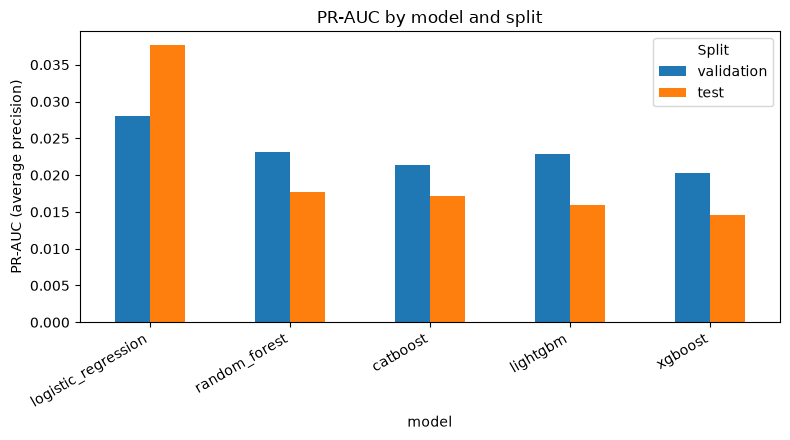

split,test,validation
model,,
logistic_regression,0.037655,0.028075
random_forest,0.017681,0.023185
catboost,0.017228,0.021320
lightgbm,0.015961,0.022886
xgboost,0.014640,0.020236


In [8]:
fig, ax = plt.subplots(figsize=(8, 4.5))
pr_auc_pivot = results.pivot(index="model", columns="split", values="pr_auc").sort_values("test", ascending=False)
pr_auc_pivot[["validation", "test"]].plot(kind="bar", ax=ax)
ax.set_ylabel("PR-AUC (average precision)")
ax.set_title("PR-AUC by model and split")
ax.legend(title="Split")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

pr_auc_pivot


## 8. ROC-AUC Comparison

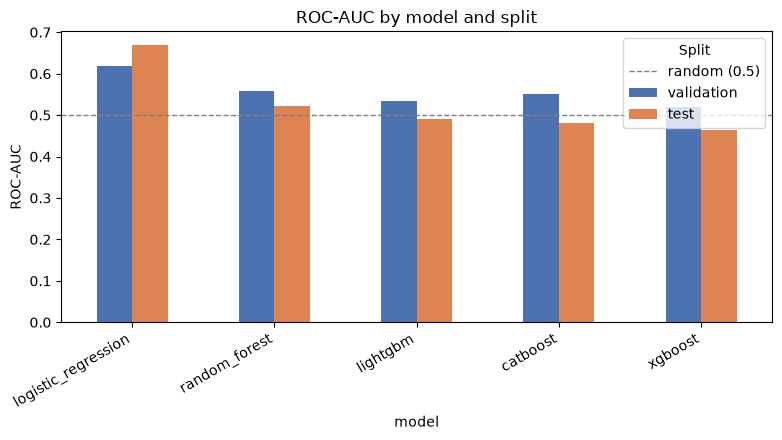

split,test,validation
model,,
logistic_regression,0.668745,0.619702
random_forest,0.521719,0.558722
lightgbm,0.489623,0.534180
catboost,0.480700,0.551053
xgboost,0.464546,0.520614


In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))
roc_auc_pivot = results.pivot(index="model", columns="split", values="roc_auc").sort_values("test", ascending=False)
roc_auc_pivot[["validation", "test"]].plot(kind="bar", ax=ax, color=["#4C72B0", "#DD8452"])
ax.axhline(0.5, color="gray", linestyle="--", linewidth=1, label="random (0.5)")
ax.set_ylabel("ROC-AUC")
ax.set_title("ROC-AUC by model and split")
ax.legend(title="Split")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

roc_auc_pivot


## 9. Precision / Recall / F1 Comparison (Test Split, Threshold = 0.5)

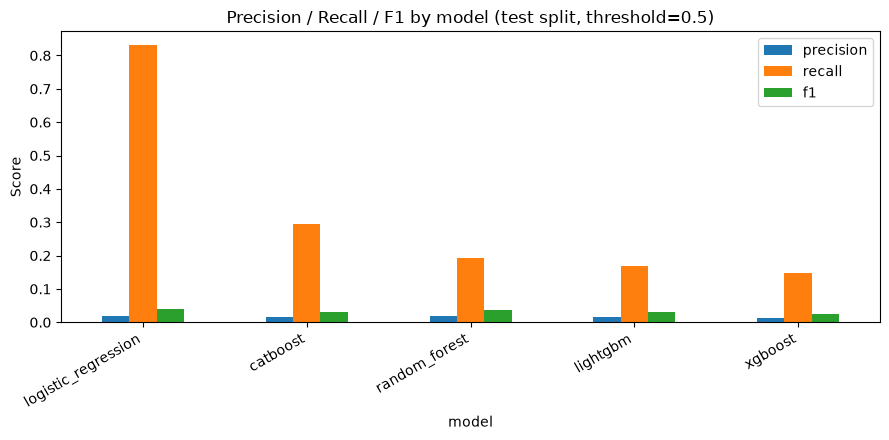

,precision,recall,f1
model,,,
logistic_regression,0.020101,0.830846,0.039253
catboost,0.016695,0.293532,0.031593
random_forest,0.019990,0.194030,0.036245
lightgbm,0.016425,0.169154,0.029943
xgboost,0.013689,0.146766,0.025042


In [10]:
prf_test = results[results["split"] == "test"].set_index("model")[["precision", "recall", "f1"]]
prf_test = prf_test.sort_values("recall", ascending=False)

fig, ax = plt.subplots(figsize=(9, 4.5))
prf_test.plot(kind="bar", ax=ax)
ax.set_ylabel("Score")
ax.set_title("Precision / Recall / F1 by model (test split, threshold=0.5)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

prf_test


## 10. Model Comparison Conclusions

**Reading these results:** Logistic Regression's `class_weight="balanced"`
setting drives it to flag the large majority of rows as high-risk at
threshold 0.5, which mechanically produces the highest recall of the five
models along with very low precision -- a predictable consequence of that
setting, not evidence of superior discrimination on its own. PR-AUC
(threshold-independent) is the fairer lens for comparing raw ranking
ability across models with very different default operating points.

Across the three gradient-boosting libraries (XGBoost, LightGBM, CatBoost),
none outperforms the two simpler Phase 5 baselines on this feature set at
these untuned default settings -- unsurprising, since boosted trees
typically need at least some tuning (tree depth, learning rate, number of
estimators, regularization) to realize their usual advantage over simpler
models, and none was applied here by design.

All five models remain well above the ~1-1.7% positive-rate floor a random
classifier's PR-AUC would sit at, but the absolute PR-AUC values are still
low in absolute terms across the board. Per the Phase 4 caveat, this is
also consistent with the underlying synthetic churn signal being
intentionally noisy rather than a modeling failure specific to any one
library.

**No model here is being called "production-ready."** This notebook's job
was a fair, apples-to-apples comparison of untuned baselines -- nothing
more.


## 11. Recommendation for Phase 7 Tuning

Based strictly on the **test-split PR-AUC** documented above (the primary
metric fixed at the start of this notebook), the model with the highest
test PR-AUC is the recommended starting point for Phase 7 hyperparameter
tuning. See the printed ranking in the cell below for the exact model name
and value, computed directly from `results` rather than hard-coded here.

This is a starting point for tuning, not a final model choice -- Phase 7
should still consider whether a different model responds better to tuning
than its current untuned PR-AUC alone suggests.


In [11]:
test_pr_auc_ranking = (
    results[results["split"] == "test"]
    .sort_values("pr_auc", ascending=False)[["model", "pr_auc", "roc_auc", "recall", "precision"]]
    .reset_index(drop=True)
)
print("Test-split PR-AUC ranking (highest first):")
display(test_pr_auc_ranking)

recommended_model = test_pr_auc_ranking.iloc[0]["model"]
recommended_pr_auc = test_pr_auc_ranking.iloc[0]["pr_auc"]
print(f"\nRecommended for Phase 7 tuning: {recommended_model} (test PR-AUC = {recommended_pr_auc:.4f})")
print("This is a starting point for tuning -- not a claim of production readiness.")


Test-split PR-AUC ranking (highest first):


,model,pr_auc,roc_auc,recall,precision
0,logistic_regression,0.037655,0.668745,0.830846,0.020101
1,random_forest,0.017681,0.521719,0.194030,0.019990
2,catboost,0.017228,0.480700,0.293532,0.016695
3,lightgbm,0.015961,0.489623,0.169154,0.016425
4,xgboost,0.014640,0.464546,0.146766,0.013689



Recommended for Phase 7 tuning: logistic_regression (test PR-AUC = 0.0377)
This is a starting point for tuning -- not a claim of production readiness.


## Save Comparison Results

Saved to `reports/model_comparison_results.csv`.


In [12]:
results_path = mc.save_comparison_results(results)
print(f"Saved -> {results_path}")
results


Saved -> /Users/dhananjaymandal/customer-retention-intelligence/reports/model_comparison_results.csv


,model,split,roc_auc,pr_auc,precision,recall,f1,true_negatives,false_positives,false_negatives,true_positives,positive_prediction_rate,threshold
0,logistic_regression,validation,0.619702,0.028075,0.020848,0.741071,0.040555,10296,15593,116,332,0.604663,0.5
1,logistic_regression,test,0.668745,0.037655,0.020101,0.830846,0.039253,8261,16282,68,334,0.666105,0.5
2,random_forest,validation,0.558722,0.023185,0.026368,0.238839,0.047492,21938,3951,341,107,0.154080,0.5
3,random_forest,test,0.521719,0.017681,0.019990,0.194030,0.036245,20719,3824,324,78,0.156424,0.5
4,xgboost,validation,0.520614,0.020236,0.020842,0.223214,0.038124,21191,4698,348,100,0.182177,0.5
5,xgboost,test,0.464546,0.014640,0.013689,0.146766,0.025042,20292,4251,343,59,0.172780,0.5
6,lightgbm,validation,0.534180,0.022886,0.023799,0.238839,0.043285,21500,4389,341,107,0.170710,0.5
7,lightgbm,test,0.489623,0.015961,0.016425,0.169154,0.029943,20471,4072,334,68,0.165965,0.5
8,catboost,validation,0.551053,0.021320,0.020492,0.345982,0.038692,18480,7409,293,155,0.287201,0.5
9,catboost,test,0.480700,0.017228,0.016695,0.293532,0.031593,17593,6950,284,118,0.283343,0.5
